In [94]:

import pandas as pd

data = {
    "Enquiry_ID": range(1001, 1031),
    "Category": [
        "Billing", "Technical", "Account", "Booking", "Billing",
        "Technical", "Account", "Booking", "Billing", "Technical",
        "Account", "Booking", "Billing", "Technical", "Account",
        "Booking", "Billing", "Technical", "Account", "Booking",
        "Billing", "Technical", "Account", "Booking", "Billing",
        "Technical", "Account", "Booking", "Billing", "Technical"
    ],
    "Channel": [
        "Email", "Phone", "Chat", "Email", "Chat",
        "Email", "Phone", "Chat", "Phone", "Email",
        "Chat", "Phone", "Email", "Chat", "Phone",
        "Email", "Chat", "Phone", "Email", "Chat",
        "Phone", "Email", "Chat", "Phone", "Email",
        "Chat", "Phone", "Email", "Chat", "Phone"
    ],
    "Response_Time_Min": [
        25, 12, 5, 40, 18, 55, 10, 8, 35, 22,
        15, 30, 45, 9, 20, 60, 14, 16, 28, 7,
        32, 48, 11, 25, 38, 6, 19, 42, 13, 17
    ],
    "Resolution_Status": [
        "Resolved", "Resolved", "Resolved", "Pending", "Resolved",
        "Resolved", "Resolved", "Resolved", "Pending", "Resolved",
        "Resolved", "Resolved", "Resolved", "Pending", "Resolved",
        "Pending", "Resolved", "Resolved", "Resolved", "Resolved",
        "Pending", "Resolved", "Resolved", "Resolved", "Resolved",
        "Resolved", "Pending", "Resolved", "Resolved", "Resolved"
    ],
    "Resolution_Time_Hours": [
        2.0, 0.5, 0.25, None, 1.5, 3.0, 0.75, 0.5, None, 2.5,
        1.0, 1.5, 2.0, None, 1.25, None, 0.75, 1.0, 2.0, 0.5,
        None, 3.5, 0.75, 1.5, 2.5, 0.5, None, 2.0, 1.0, 1.25
    ],
    "Customer_Rating": [
        4, 5, 5, None, 4, 3, 5, 4, None, 4,
        5, 4, 3, None, 4, None, 5, 4, 3, 5,
        None, 4, 5, 4, 3, 5, None, 4, 4, 5
    ],
    "Agent": [
        "Ama", "Kojo", "Esi", "Yaw", "Ama",
        "Kojo", "Esi", "Yaw", "Ama", "Kojo",
        "Esi", "Yaw", "Ama", "Kojo", "Esi",
        "Yaw", "Ama", "Kojo", "Esi", "Yaw",
        "Ama", "Kojo", "Esi", "Yaw", "Ama",
        "Kojo", "Esi", "Yaw", "Ama", "Kojo"
    ]
}

df = pd.DataFrame(data)


In [ ]:
df.head()

,Enquiry_ID,Category,Channel,Response_Time_Min,Resolution_Status,Resolution_Time_Hours,Customer_Rating,Agent
0,1001,Billing,Email,25,Resolved,2.00,4.0,Ama
1,1002,Technical,Phone,12,Resolved,0.50,5.0,Kojo
2,1003,Account,Chat,5,Resolved,0.25,5.0,Esi
3,1004,Booking,Email,40,Pending,NaN,NaN,Yaw
4,1005,Billing,Chat,18,Resolved,1.50,4.0,Ama


In [ ]:
df.columns

Index(['Enquiry_ID', 'Category', 'Channel', 'Response_Time_Min',
       'Resolution_Status', 'Resolution_Time_Hours', 'Customer_Rating',
       'Agent'],
      dtype='object')

In [ ]:
df.shape

(30, 8)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Enquiry_ID             30 non-null     int64  
 1   Category               30 non-null     object 
 2   Channel                30 non-null     object 
 3   Response_Time_Min      30 non-null     int64  
 4   Resolution_Status      30 non-null     object 
 5   Resolution_Time_Hours  24 non-null     float64
 6   Customer_Rating        24 non-null     float64
 7   Agent                  30 non-null     object 
dtypes: float64(2), int64(2), object(4)
memory usage: 2.0+ KB


In [ ]:
df.isnull().sum()

,0
Enquiry_ID,0
Category,0
Channel,0
Response_Time_Min,0
Resolution_Status,0
Resolution_Time_Hours,6
Customer_Rating,6
Agent,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
Total_enquiries = len(df)

In [ ]:
Resolved = (df["Resolution_Status"] == "Resolved").sum()
Resolved

np.int64(24)

In [ ]:
Resolution_rate = (Resolved/Total_enquiries )*100;Resolution_rate

np.float64(80.0)

In [ ]:
average_response_time = df['Response_Time_Min'].mean();average_response_time

np.float64(24.166666666666668)

In [ ]:
longest_response = max(df['Response_Time_Min']); longest_response

60

In [ ]:
df.groupby(df.Category)["Response_Time_Min"].mean()

,Response_Time_Min
Category,
Account,15.428571
Billing,27.500000
Booking,30.285714
Technical,23.125000


In [ ]:
Average_response_by_channel =df.groupby(df.Channel)["Response_Time_Min"].mean()

In [ ]:
Average_response_by_Customer_Rating=df.groupby(df.Customer_Rating)["Response_Time_Min"].mean()

In [ ]:
df.groupby(df.Resolution_Status)["Customer_Rating"].mean()

,Customer_Rating
Resolution_Status,
Pending,NaN
Resolved,4.208333


In [ ]:
import matplotlib.pyplot as plt

In [76]:
y = df['Response_Time_Min']
x = df['Channel']

Text(0, 0.5, 'Average response in minute')

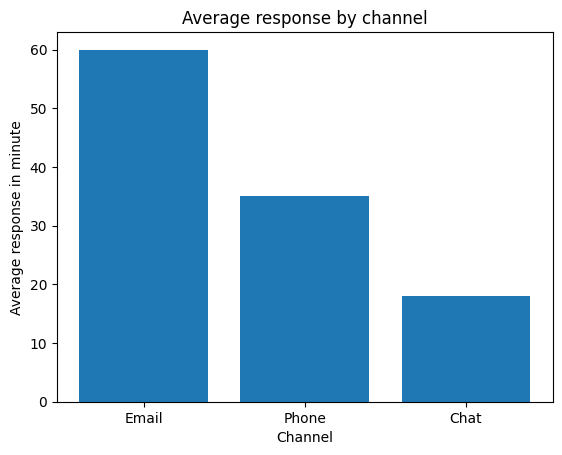

In [77]:
plt.bar(x,y)
plt.title("Average response by channel")
plt.xlabel("Channel")
plt.ylabel("Average response in minute")

Text(0, 0.5, 'Average response in minute')

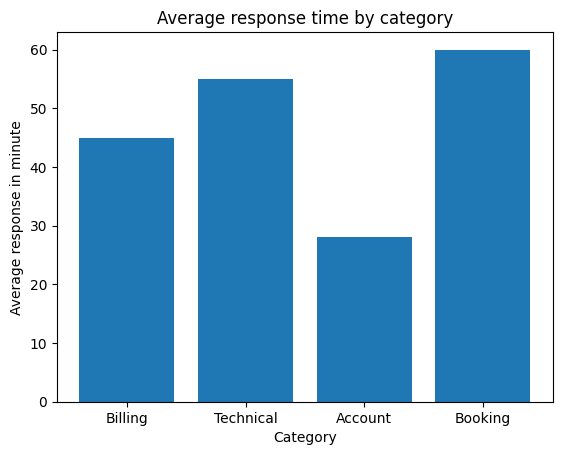

In [78]:
y = df['Response_Time_Min']
x = df['Category']

plt.bar(x,y)
plt.title("Average response time by category")
plt.xlabel("Category")
plt.ylabel("Average response in minute")

In [89]:
h = df.dropna(subset=["Customer_Rating"]);h

,Enquiry_ID,Category,Channel,Response_Time_Min,Resolution_Status,Resolution_Time_Hours,Customer_Rating,Agent
0,1001,Billing,Email,25,Resolved,2.00,4.0,Ama
1,1002,Technical,Phone,12,Resolved,0.50,5.0,Kojo
2,1003,Account,Chat,5,Resolved,0.25,5.0,Esi
4,1005,Billing,Chat,18,Resolved,1.50,4.0,Ama
5,1006,Technical,Email,55,Resolved,3.00,3.0,Kojo
6,1007,Account,Phone,10,Resolved,0.75,5.0,Esi
7,1008,Booking,Chat,8,Resolved,0.50,4.0,Yaw
9,1010,Technical,Email,22,Resolved,2.50,4.0,Kojo
10,1011,Account,Chat,15,Resolved,1.00,5.0,Esi
11,1012,Booking,Phone,30,Resolved,1.50,4.0,Yaw


Text(0, 0.5, 'Average response in minute')

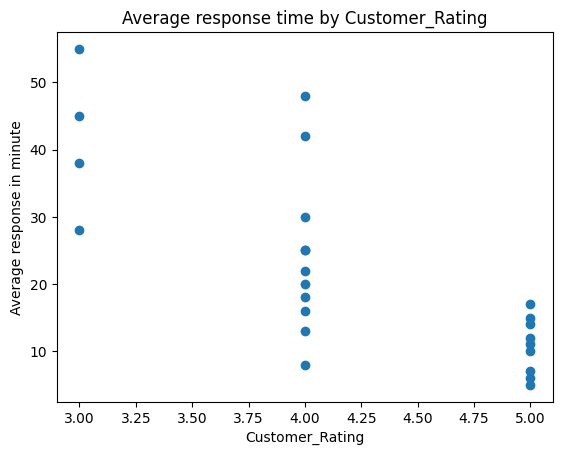

In [91]:
y = h['Response_Time_Min']
x = h['Customer_Rating']

plt.scatter(x,y)
plt.title("Average response time by Customer_Rating")
plt.xlabel("Customer_Rating")
plt.ylabel("Average response in minute")

In [96]:
df.groupby(df.Category)["Resolution_Time_Hours"].mean()

,Resolution_Time_Hours
Category,
Account,1.000
Billing,1.625
Booking,1.200
Technical,1.750
